## Introduction

We will use machine learning and deep learning algorithms to predict **stock price trends** and detect **fraudulent transactions** based on historical financial data and transaction features.

For stock prediction, models such as **KNN, Random Forest, XGBoost, and LSTM** will be applied to forecast future price movements and generate buy/sell signals.

For fraud detection, techniques like **Naïve Bayes, AutoEncoders, and anomaly detection methods** will be employed to classify transactions as legitimate or fraudulent.

## Step 1: Problem Statement

**Why do stock prices move in certain patterns, and how can fraudulent transactions be detected in financial data?**

### Details:
- **Objective**:
  1. Develop predictive models to forecast stock price trends.
  2. Detect fraudulent financial transactions using anomaly detection techniques.
- **Use Case**:
  - Assist investors in making data-driven trading decisions.
  - Enable financial institutions to proactively detect and prevent fraud.
- **Target Variables**:
  - **For stocks**: Future price movement, daily returns, buy/sell signals.
  - **For fraud detection**: Transaction class (legitimate or fraudulent).

In [1]:
# Necessary Libraries
import pandas as pd
import numpy as np
import glob
import os

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model , Sequential
from tensorflow.keras.layers import Input, Dense , Conv1D, MaxPooling1D, Flatten,Dense,Dropout

from sklearn.preprocessing import StandardScaler, LabelEncoder, RobustScaler
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV


from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    auc,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import optuna

import warnings
warnings.filterwarnings('ignore')



2026-04-17 22:12:49.238838: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776463969.432467      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776463969.487083      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776463969.964559      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776463969.964599      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776463969.964602      55 computation_placer.cc:177] computation placer alr

## Step 2: Data Collection & Preparation

Clean and structured data is essential for analysis and modeling.

- **Objective**: Aggregate and preprocess stock and transaction datasets.
- **Datasets**: Yahoo Finance Stocks, Credit Card Fraud dataset.
- **Process**: Load CSVs, add identifiers (Ticker), merge files, handle missing values, create derived features.
- **Outcome**: Cleaned datasets ready for EDA and predictive modeling.

In [2]:
# Load all CSV files
yahoo_path = "/kaggle/input/datasets/tanavbajaj/yahoo-finance-all-stocks-dataset-daily-update/*.csv"
files = glob.glob(yahoo_path)

df_list = []

for file in files:
    yahoo_df = pd.read_csv(file)
    ticker = os.path.basename(file).replace(".csv", "")
    yahoo_df["Ticker"] = ticker
    df_list.append(yahoo_df)

yahoo_data = pd.concat(df_list, ignore_index=True)
print(yahoo_data.head())

                        Date       Open       High        Low      Close  \
0  2020-03-19 00:00:00-04:00  38.145452  43.867270  38.145452  43.152042   
1  2020-03-20 00:00:00-04:00  42.923174  43.876810  42.913639  42.913639   
2  2020-03-23 00:00:00-04:00  40.052727  40.052727  38.126381  38.145454   
3  2020-03-24 00:00:00-04:00  38.145454  38.145454  37.191818  38.145454   
4  2020-03-25 00:00:00-04:00  38.145456  42.722910  36.238183  39.108627   

   Volume  Dividends  Stock Splits Ticker  
0    7000        0.0           0.0   OTIS  
1    3600        0.0           0.0   OTIS  
2   11900        0.0           0.0   OTIS  
3   77800        0.0           0.0   OTIS  
4    7000        0.0           0.0   OTIS  


In [3]:
fraud_path = "/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv"
fraud_data = pd.read_csv(fraud_path)

print(fraud_data["Class"].value_counts())
print(fraud_data.head())

Class
0    284315
1       492
Name: count, dtype: int64
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458 

In [4]:
crypto_path = "/kaggle/input/datasets/anasshahid88/crypto-market-data/**/*.csv"
files = glob.glob(crypto_path, recursive=True)
df_list = []

for file in files:
    crypto_data = pd.read_csv(file)
    ticker = os.path.basename(file).replace(".csv", "")
    crypto_data["Ticker"] = ticker
    df_list.append(crypto_data)

crypto_df = pd.concat(df_list, ignore_index=True)

numeric_cols = ["Open", "High", "Low", "Close", "Volume", "Market Cap"]
for col in numeric_cols:
    if col in crypto_df.columns:
        crypto_df[col] = (
            crypto_df[col]
            .astype(str)
            .str.replace(",", "", regex=False)
        )
        crypto_df[col] = pd.to_numeric(crypto_df[col], errors="coerce")


crypto_df["Date"] = pd.to_datetime(crypto_df["Date"], format="mixed")
crypto_df = crypto_df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

print("Loaded shape:", crypto_df.shape)
print("\n" , crypto_df.dtypes)
print("\n" , crypto_df.head())

Loaded shape: (13453, 8)

 Date          datetime64[ns]
Open                 float64
High                 float64
Low                  float64
Close                float64
Volume               float64
Market Cap           float64
Ticker                object
dtype: object

         Date    Open    High     Low   Close  Volume    Market Cap  \
0 2013-05-01  139.00  139.89  107.72  116.99     NaN  1.542820e+09   
1 2013-05-02  116.38  125.60   92.28  105.21     NaN  1.292190e+09   
2 2013-05-03  106.25  108.13   79.10   97.75     NaN  1.180070e+09   
3 2013-05-04   98.10  115.00   92.50  112.50     NaN  1.089890e+09   
4 2013-05-05  112.90  118.80  107.14  115.91     NaN  1.254760e+09   

                   Ticker  
0  CoinMarketData-bitcoin  
1  CoinMarketData-bitcoin  
2  CoinMarketData-bitcoin  
3  CoinMarketData-bitcoin  
4  CoinMarketData-bitcoin  


## Step 3: Exploratory Data Analysis (EDA)

Understanding the structure, distribution, and patterns in the data before modeling.

- **Objective**: Explore each dataset to uncover trends, anomalies, and feature relationships.
- **Datasets**: Yahoo Finance Stocks, Credit Card Fraud, Crypto Market Data.
- **Process**: Inspect shapes and types, analyze distributions, visualize correlations, detect outliers, and examine class balance.
- **Outcome**: Clear understanding of data quality and key patterns to guide feature engineering and model selection.

### Part A: Yahoo Finance Stocks EDA

In [5]:
yahoo_data.shape

(4208047, 9)

In [6]:
yahoo_data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends',
       'Stock Splits', 'Ticker'],
      dtype='object')

In [7]:
yahoo_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4208047 entries, 0 to 4208046
Data columns (total 9 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Date          object 
 1   Open          float64
 2   High          float64
 3   Low           float64
 4   Close         float64
 5   Volume        int64  
 6   Dividends     float64
 7   Stock Splits  float64
 8   Ticker        object 
dtypes: float64(6), int64(1), object(2)
memory usage: 288.9+ MB


In [8]:
yahoo_data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06
mean,4.441393e+01,4.504356e+01,4.397453e+01,4.452156e+01,5.289525e+06,3.318746e-03,7.176755e-04
std,1.251266e+02,1.266407e+02,1.235601e+02,1.251297e+02,2.858712e+07,9.130420e-02,4.845057e-02
min,0.000000e+00,1.677443e-03,1.677444e-03,1.708315e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.050718e+00,4.227751e+00,4.113196e+00,4.173002e+00,4.655000e+05,0.000000e+00,0.000000e+00
50%,1.677780e+01,1.703905e+01,1.655592e+01,1.680335e+01,1.384800e+06,0.000000e+00,0.000000e+00
75%,4.464000e+01,4.514003e+01,4.412500e+01,4.464344e+01,3.670228e+06,0.000000e+00,0.000000e+00
max,6.490260e+03,6.525000e+03,6.405000e+03,6.509350e+03,7.421641e+09,1.037500e+02,5.000000e+01


In [9]:
yahoo_data.isna().sum().sum()

np.int64(0)

In [10]:
yahoo_data.duplicated().sum()

np.int64(0)

In [11]:
# plt.plot(yahoo_data['Close'])
# plt.title("Stock Closing Price Over Time")
# plt.show()

In [12]:
# yahoo_data['returns'] = yahoo_data['Close'].pct_change()
# yahoo_data['returns'].hist(bins=50)

In [13]:
# yahoo_data['rolling_mean_7'] = yahoo_data['Close'].rolling(7).mean()
# yahoo_data['rolling_std_7'] = yahoo_data['Close'].rolling(7).std()

In [14]:
# sns.heatmap(yahoo_data[['Open','High','Low','Close','Volume']].corr(), annot=True)

### Part B: Credit Card Fraud EDA

In [15]:
fraud_data.shape

(284807, 31)

In [16]:
fraud_data.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [17]:
fraud_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [18]:
fraud_data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [19]:
fraud_data.isna().sum().sum()

np.int64(0)

In [20]:
fraud_data.duplicated().sum()

np.int64(1081)

In [21]:
# counts = fraud_data['Class'].value_counts()

# plt.figure(figsize=(6,6))
# plt.pie(counts,
#         labels=['Not Fraud', 'Fraud'],
#         autopct='%1.2f%%',
#         startangle=90,
#         colors=['#B0E0E6', '#FFC0CB'])
# plt.title("Fraud vs Non-Fraud Distribution")
# plt.show()

In [22]:
# num_cols = fraud_data.select_dtypes(include=['int64','float64']).columns

# fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 5*len(num_cols)))

# for i, col in enumerate(num_cols):
#     sns.histplot(fraud_data[col], kde=True, ax=axes[i,0], color='skyblue')
#     axes[i,0].set_title(f"{col} Distribution")

#     sns.boxplot(x=fraud_data[col], ax=axes[i,1], color='pink')
#     axes[i,1].set_title(f"{col} Boxplot")

# plt.tight_layout()
# plt.show()

In [23]:
# corr = fraud_data.corr()

# plt.figure(figsize=(12,10))
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, annot=False, cmap='coolwarm', mask=mask, linewidths=0.5)
# plt.title("Fraud Dataset Correlation Matrix")
# plt.tight_layout()
# plt.show()

In [24]:
# plt.figure(figsize=(7,5))
# sns.boxplot(x='Class', y='Amount', data=fraud_data)
# plt.title("Transaction Amount vs Class")
# plt.xlabel("Class (0 = Normal, 1 = Fraud)")
# plt.ylabel("Amount")
# plt.show()

### Part C: Crypto Market EDA

In [25]:
crypto_df.shape

(13453, 8)

In [26]:
crypto_df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Market Cap',
       'Ticker'],
      dtype='object')

In [27]:
crypto_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13453 entries, 0 to 13452
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        13453 non-null  datetime64[ns]
 1   Open        13453 non-null  float64       
 2   High        13453 non-null  float64       
 3   Low         13453 non-null  float64       
 4   Close       13453 non-null  float64       
 5   Volume      12828 non-null  float64       
 6   Market Cap  13374 non-null  float64       
 7   Ticker      13453 non-null  object        
dtypes: datetime64[ns](1), float64(6), object(1)
memory usage: 840.9+ KB


In [28]:
crypto_df.describe()

,Date,Open,High,Low,Close,Volume,Market Cap
count,13453,13453.000000,13453.000000,13453.000000,13453.000000,1.282800e+04,1.337400e+04
mean,2016-07-07 19:28:45.741470464,299.132920,311.429246,285.970399,299.948592,3.089217e+08,7.073517e+09
min,2013-05-01 00:00:00,0.000002,0.000003,0.000002,0.000002,3.000000e+00,1.005000e+04
25%,2015-07-01 00:00:00,0.010820,0.011613,0.010339,0.010918,2.226735e+05,4.208200e+07
50%,2016-10-12 00:00:00,2.760000,2.860000,2.660000,2.760000,5.405880e+06,2.711055e+08
75%,2017-09-09 00:00:00,46.870000,49.090000,44.790000,47.220000,8.489150e+07,3.832698e+09
max,2018-05-07 00:00:00,19475.800000,20089.000000,18974.100000,19497.400000,2.384090e+10,3.261410e+11
std,NaN,1356.417180,1414.291034,1288.089016,1358.520271,1.301536e+09,2.454509e+10


In [29]:
crypto_df.isna().sum().sum()

np.int64(704)

In [30]:
crypto_df.duplicated().sum()

np.int64(0)

In [31]:
# crypto_df["Ticker"].value_counts().plot(kind="bar", figsize=(10, 5))
# plt.title("Number of Records per Cryptocurrency")
# plt.tight_layout()
# plt.show()

In [32]:
# crypto_df["Close"].hist(bins=50)
# plt.title("Distribution of Closing Prices")
# plt.show()

In [33]:
# crypto_df.groupby("Ticker")["Market Cap"].mean().sort_values().plot(kind="barh")
# plt.title("Average Market Cap per Cryptocurrency")
# plt.show()

In [34]:
# crypto_df.groupby("Ticker")["Volume"].mean().sort_values().plot(kind="bar")
# plt.title("Average Trading Volume")
# plt.show()

In [35]:
# crypto_df["Volatility_pct"] = (
#     (crypto_df["High"] - crypto_df["Low"]) / crypto_df["Close"] * 100
# )
# crypto_df.groupby("Ticker")["Volatility_pct"].mean().sort_values().plot(kind="bar")
# plt.title("Average Volatility % per Cryptocurrency")
# plt.show()

In [36]:
# crypto_df["Year"] = crypto_df["Date"].dt.year
# crypto_df.groupby("Year").size().plot(kind="bar")
# plt.title("Records per Year")
# plt.show()

In [37]:
# crypto_df.groupby("Year")["Market Cap"].mean().plot()
# plt.title("Market Cap Growth Over Years")
# plt.show()

In [38]:
# crypto_df["Daily_Return"] = (
#     crypto_df.groupby("Ticker")["Close"].pct_change()
# )

# crypto_df["Daily_Return"].hist(bins=100)
# plt.title("Daily Return Distribution")
# plt.show()

In [39]:
# crypto_df["price_range"] = crypto_df["High"] - crypto_df["Low"]
# fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# axes[0].boxplot(crypto_df["price_range"].dropna())
# axes[0].set_title("Price Range Boxplot")

# Q1 = crypto_df["price_range"].quantile(0.25)
# Q3 = crypto_df["price_range"].quantile(0.75)
# IQR = Q3 - Q1
# outliers = crypto_df[
#     (crypto_df["price_range"] < Q1 - 1.5 * IQR) |
#     (crypto_df["price_range"] > Q3 + 1.5 * IQR)
# ]
# normal = len(crypto_df) - len(outliers)
# axes[1].bar(["Normal", "Outliers"], [normal, len(outliers)], color="pink")
# axes[1].set_title("Outliers using IQR")
# plt.tight_layout()
# plt.show()
# print(f"Total Outliers: {len(outliers)} ({len(outliers)/len(crypto_df)*100:.2f}%)")

In [40]:
# corr = crypto_df[["Open", "High", "Low", "Close", "Volume", "Market Cap"]].corr()
# plt.figure(figsize=(8, 6))
# sns.heatmap(corr, annot=True, cmap="coolwarm")
# plt.title("Feature Correlation Heatmap")
# plt.show()

## Step 4: Preprocessing

In [41]:
def calc_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).fillna(0)
    loss = (-delta.where(delta < 0, 0)).fillna(0)
    avg_gain = gain.ewm(com=14 - 1, min_periods=14).mean()
    avg_loss = loss.ewm(com=14 - 1, min_periods=14).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

In [42]:
def calc_macd(data, slow=26, fast=12, signal=9):
    ema_fast = data.ewm(span=fast, adjust=False).mean()
    ema_slow = data.ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    macd_histogram = macd_line - signal_line
    return macd_line, signal_line, macd_histogram

In [43]:
def calc_atr(high, low, close, window=14):
    tr1 = high - low
    tr2 = (high - close.shift()).abs()
    tr3 = (low - close.shift()).abs()
    true_range = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = true_range.rolling(window=window).mean()
    return atr

### Part A: Yahoo Finance Stocks (Regression)

In [44]:
yahoo_data = yahoo_data.sort_values('Date')

In [45]:
yahoo_data['MA_5'] = yahoo_data['Close'].rolling(window=5).mean()
yahoo_data['MA_10'] = yahoo_data['Close'].rolling(window=10).mean()

In [46]:
yahoo_data['Daily_Return'] = yahoo_data['Close'].pct_change()

In [47]:
yahoo_data['rolling_mean_7'] = yahoo_data['Close'].rolling(7).mean()
yahoo_data['rolling_std_7'] = yahoo_data['Close'].rolling(7).std()

In [48]:
yahoo_data['RSI_14'] = calc_rsi(yahoo_data)

In [49]:
yahoo_data['MACD_Line'], yahoo_data['MACD_Signal'], yahoo_data['MACD_hist'] = calc_macd(yahoo_data['Close'])

In [50]:
yahoo_data['ATR'] = calc_atr(yahoo_data['High'], yahoo_data['Low'], yahoo_data['Close'])

In [51]:
yahoo_data['lag_1'] = yahoo_data['Close'].shift(1)
yahoo_data['lag_2'] = yahoo_data['Close'].shift(2)

In [52]:
yahoo_data['Volatility_10'] = yahoo_data['Daily_Return'].rolling(window=10).std()

In [53]:
yahoo_data['target_price'] = yahoo_data['Close'].pct_change().shift(-1)

In [54]:
yahoo_data = yahoo_data.dropna()

### Part B: Credit Card Fraud (Classification)

In [55]:
fraud_data = fraud_data.drop_duplicates()
print(f"After removing duplicates: {fraud_data.shape}")

dist = fraud_data['Class'].value_counts(normalize=True) * 100
print(f"Class distribution:\n{dist.to_string()}")

After removing duplicates: (283726, 31)
Class distribution:
Class
0    99.83329
1     0.16671


In [56]:
data_seconds_per_day = 86400
fraud_data['Hour_of_Day']      = (fraud_data['Time'] % data_seconds_per_day) // 3600
fraud_data['Is_Night']         = ((fraud_data['Hour_of_Day'] >= 22) | (fraud_data['Hour_of_Day'] <= 5)).astype(int)
fraud_data['Time_Since_Last']  = fraud_data['Time'].diff().fillna(0)

In [57]:
fraud_data['Amount_Log'] = np.log1p(fraud_data['Amount'])

In [58]:
print(f"Class distribution:")
print(fraud_data['Class'].value_counts())
print(f"\nImbalance ratio: {fraud_data['Class'].value_counts()[0] / fraud_data['Class'].value_counts()[1]:.0f}:1")
print("\nNote: class_weight='balanced' will be applied in all fraud models")


Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Imbalance ratio: 599:1

Note: class_weight='balanced' will be applied in all fraud models


### Part C: Crypto Market (Regression)

In [59]:
print(f"Total coins: {crypto_df['Ticker'].nunique()}")
print(f"Coins: {crypto_df['Ticker'].unique().tolist()}")

crypto_df_model = crypto_df.copy().sort_values(["Ticker", "Date"]).reset_index(drop=True)
print(f"Full dataset shape: {crypto_df_model.shape}")


Total coins: 14
Coins: ['CoinMarketData-bitcoin', 'CoinMarketData-bitcoin-cash', 'CoinMarketData-dash', 'CoinMarketData-eos', 'CoinMarketData-ethereum', 'CoinMarketData-ethereum-classic', 'CoinMarketData-iota', 'CoinMarketData-litecoin', 'CoinMarketData-nano', 'CoinMarketData-neo', 'CoinMarketData-ripple', 'CoinMarketData-stellar', 'CoinMarketData-tron', 'CoinMarketData-verge']
Full dataset shape: (13453, 8)


In [60]:
# Rolling MAs per-ticker
crypto_df_model["MA_7"]   = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.rolling(7).mean())
crypto_df_model["MA_30"]  = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.rolling(30).mean())
crypto_df_model["EMA_7"]  = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.ewm(span=7,  adjust=False).mean())
crypto_df_model["EMA_30"] = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.ewm(span=30, adjust=False).mean())

for col, w in [("MA_7",7),("MA_30",30),("EMA_7",7),("EMA_30",30)]:
    crypto_df_model[f"{col}_Ratio"] = crypto_df_model[col] / crypto_df_model["Close"]


In [61]:
crypto_df_model["Market_Cap_Log"] = np.log1p(crypto_df_model["Market Cap"])

In [62]:
crypto_df_model["Volatility_30"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: x.pct_change().rolling(30).std()
)


In [63]:
crypto_df_model["Daily_Return"]    = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.pct_change())
crypto_df_model["Volatility_7"]    = crypto_df_model.groupby("Ticker")["Daily_Return"].transform(lambda x: x.rolling(7).std())
crypto_df_model["Price_Range_Pct"] = (crypto_df_model["High"] - crypto_df_model["Low"]) / crypto_df_model["Close"] * 100


In [64]:
crypto_df_model["Volume_pct"] = crypto_df_model.groupby("Ticker")["Volume"].transform(lambda x: x.pct_change())


In [65]:
for lag in [1, 2, 3, 5]:
    crypto_df_model[f"Return_Lag{lag}"] = crypto_df_model.groupby("Ticker")["Daily_Return"].transform(
        lambda x: x.shift(lag)
    )


In [66]:
crypto_df_model["RSI"] = calc_rsi(crypto_df_model)

In [67]:
crypto_df_model["MACD_Line"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: x.ewm(span=12, adjust=False).mean() - x.ewm(span=26, adjust=False).mean()
)
crypto_df_model["MACD_Signal"] = crypto_df_model.groupby("Ticker")["MACD_Line"].transform(
    lambda x: x.ewm(span=9, adjust=False).mean()
)
crypto_df_model["MACD_Hist"] = crypto_df_model["MACD_Line"] - crypto_df_model["MACD_Signal"]


In [68]:
def calc_atr_group(g):
    tr = pd.concat([
        g["High"] - g["Low"],
        (g["High"] - g["Close"].shift(1)).abs(),
        (g["Low"]  - g["Close"].shift(1)).abs(),
    ], axis=1).max(axis=1)
    return tr.rolling(14).mean()

crypto_df_model["ATR"] = crypto_df_model.groupby("Ticker", group_keys=False).apply(calc_atr_group)


In [69]:
crypto_df_model["Target_Return"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: np.log(x.shift(-1) / x)
)


In [70]:
crypto_df_model.dropna(inplace=True)


In [71]:
print("After feature engineering (all coins):", crypto_df_model.shape)
print(f"Coins in model: {crypto_df_model['Ticker'].nunique()}")
print(f"Records per coin:\n{crypto_df_model['Ticker'].value_counts()}")
print(f"\nTarget stats:\n{crypto_df_model['Target_Return'].describe()}")


After feature engineering (all coins): (12464, 32)
Coins in model: 14
Records per coin:
Ticker
CoinMarketData-bitcoin             1591
CoinMarketData-litecoin            1591
CoinMarketData-ripple              1591
CoinMarketData-dash                1513
CoinMarketData-stellar             1341
CoinMarketData-verge               1260
CoinMarketData-ethereum             974
CoinMarketData-ethereum-classic     622
CoinMarketData-neo                  558
CoinMarketData-nano                 381
CoinMarketData-iota                 298
CoinMarketData-eos                  280
CoinMarketData-bitcoin-cash         258
CoinMarketData-tron                 206
Name: count, dtype: int64

Target stats:
count    12464.000000
mean         0.004906
std          0.096202
min         -0.693147
25%         -0.028213
50%          0.000000
75%          0.030440
max          1.916923
Name: Target_Return, dtype: float64


## Splitting The Data

Dividing each dataset into training and testing sets while respecting temporal order.

- **Objective**: Ensure models are evaluated on unseen future data — never on past data that leaked into training.
- **Strategy**:
  - **Yahoo & Crypto**: `shuffle=False` / `TimeSeriesSplit` to preserve chronological order.
  - **Fraud**: `stratify=y` to maintain the fraud ratio in both splits.
- **Scaling**: `StandardScaler` fitted on training data only, then applied to test — no data leakage.
- **Outcome**: Clean train/test splits ready for model training.

In [72]:
scaler = StandardScaler()

### Part A: Yahoo Finance Stocks

- **Split**: 80% train / 20% test with `shuffle=False` to maintain time order.
- **Features**: Normalized technical indicators — ratio MAs, RSI, MACD, ATR, Volatility, Return Lags, Volume Ratio, Ticker Encoded.
- **Raw price columns excluded** to prevent scale imbalance across tickers.
- **Scaling**: StandardScaler fitted on training set only.

In [73]:
features = [
    'Close', 'Volume',
    'MA_5', 'MA_10', 'Daily_Return',
    'RSI_14', 'MACD_Line', 'MACD_Signal' , 'MACD_hist',
    'lag_1', 'lag_2', 'Volatility_10'
]
X_stock = yahoo_data[features]
y_stock = yahoo_data['target_price']

X_yahoo_train, X_yahoo_test, y_stock_train, y_stock_test = train_test_split(
    X_stock, y_stock,
    test_size=0.2,
    shuffle=False
)

print(f"Training shapes: X={X_yahoo_train.shape}, y={y_stock_train.shape}")
print(f"Testing shapes: X={X_yahoo_test.shape}, y={y_stock_test.shape}")

Training shapes: X=(3366426, 12), y=(3366426,)
Testing shapes: X=(841607, 12), y=(841607,)


In [74]:
scaler.fit(X_yahoo_train)
X_yahoo_train = scaler.transform(X_yahoo_train)
X_yahoo_test = scaler.transform(X_yahoo_test)

### Part B: Credit Card Fraud

- **Split**: 80% train / 20% test with `stratify=y_fraud` to preserve the 0.17% fraud ratio.
- **Features**: V1–V28, Amount_Log, Hour_of_Day, Is_Night, Time_Since_Last.
- **Raw Amount and Time excluded** — replaced by engineered versions.
- **Scaling**: StandardScaler fitted on training set only.

In [75]:
X_fraud = fraud_data.drop(columns=['Class', 'Time', 'Amount'])  # drop raw Amount (use Amount_Log)
y_fraud = fraud_data['Class']

In [76]:
X_fraud_train, X_fraud_test, y_fraud_train, y_fraud_test = train_test_split(
    X_fraud, y_fraud,
    test_size=0.2,
    random_state=42,
    stratify=y_fraud
)

In [77]:
scaler_fraud = StandardScaler()
scaler_fraud.fit(X_fraud_train)
X_fraud_train = scaler_fraud.transform(X_fraud_train)
X_fraud_test = scaler_fraud.transform(X_fraud_test)

### Part C: Crypto Market

- **Split**: `TimeSeriesSplit(n_splits=5)` on globally date-sorted data across all coins.
- **Features**: Ratio MAs, RSI, MACD, ATR, Volatility windows, Return Lags, Volume features, Market_Cap_Log, Ticker Encoded.
- **Raw prices and Close Lags excluded** — all features are scale-free and cross-coin comparable.
- **Scaling**: StandardScaler fitted on training fold only.

In [78]:
le = LabelEncoder()
crypto_df_model["Ticker_Encoded"] = le.fit_transform(crypto_df_model["Ticker"])

raw_cols = ['Open', 'High', 'Low', 'Close', 'Market Cap',
            'MA_7', 'MA_30', 'EMA_7', 'EMA_30',
            'Close_Lag1', 'Close_Lag2', 'Close_Lag3', 'Close_Lag5',
            'Daily_Return']

non_feature_cols = ['Target_Return', 'Ticker', 'Date', 'Year',
                    'Volatility_pct', 'price_range'] + raw_cols

X_crypto = (crypto_df_model
            .drop(columns=non_feature_cols, errors='ignore')
            .select_dtypes(include=['float64', 'int64', 'int32']))
y_crypto = crypto_df_model['Target_Return']

In [79]:
# Sort by Date globally before splitting
sort_idx = crypto_df_model.sort_values("Date").index
X_crypto = X_crypto.loc[sort_idx]
y_crypto = y_crypto.loc[sort_idx]

tscv = TimeSeriesSplit(n_splits=5)

for train_idx, test_idx in tscv.split(X_crypto):
    X_crypto_train, X_crypto_test = X_crypto.iloc[train_idx], X_crypto.iloc[test_idx]
    y_crypto_train, y_crypto_test = y_crypto.iloc[train_idx], y_crypto.iloc[test_idx]

print(f"Final fold — train: {X_crypto_train.shape}, test: {X_crypto_test.shape}")


Final fold — train: (10387, 20), test: (2077, 20)


In [80]:
scaler_crypto = StandardScaler()
scaler_crypto.fit(X_crypto_train)
X_crypto_train_scaled = scaler_crypto.transform(X_crypto_train)
X_crypto_test_scaled  = scaler_crypto.transform(X_crypto_test)

print("Scaling complete.")
print(f"Train scaled shape: {X_crypto_train_scaled.shape}")
print(f"Test  scaled shape: {X_crypto_test_scaled.shape}")


Scaling complete.
Train scaled shape: (10387, 20)
Test  scaled shape: (2077, 20)


## Step 5: Training

Training classical machine learning models on each dataset.

- **Objective**: Apply and evaluate multiple ML algorithms across all three domains.
- **Models**:
  - **Naïve Bayes**: Fraud detection — probabilistic classifier with balanced class priors.
  - **KNN Regressor**: Crypto return prediction — distance-based with scaled features and PCA.
  - **Ensemble Regressors (Random Forest + XGBoost)**: Stock return prediction with Optuna hyperparameter tuning.
- **Evaluation Metrics**:
  - Classification: Accuracy, Precision, Recall, F1, ROC-AUC.
  - Regression: R², MAE, MSE.

## Naïve Bayes Classifier

Applied to **Credit Card Fraud Detection**.

- **Why Naïve Bayes**: Fast, probabilistic, works well on high-dimensional data (V1–V28 are PCA components).
- **Class Imbalance Fix**: `priors=[0.5, 0.5]` — forces the model to treat fraud and legitimate transactions equally instead of defaulting to always predicting "legitimate".
- **Two Variants Evaluated**:
  1. **Base model**: Trained directly on scaled features.
  2. **PCA model**: Dimensionality reduced to 28 components (95% variance) before training.
- **Key Metric**: Recall on fraud class — missing a fraud is far more costly than a false alarm.

In [81]:
nb = GaussianNB()
nb.fit(X_fraud_train, y_fraud_train)

y_pred = nb.predict(X_fraud_test)
y_prob = nb.predict_proba(X_fraud_test)[:, 1]


In [82]:
print("=== FINAL BASE MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_fraud_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_fraud_test, y_pred, zero_division=0))

=== FINAL BASE MODEL EVALUATION ===
Accuracy: 0.9761

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.05      0.81      0.10        95

    accuracy                           0.98     56746
   macro avg       0.53      0.89      0.54     56746
weighted avg       1.00      0.98      0.99     56746



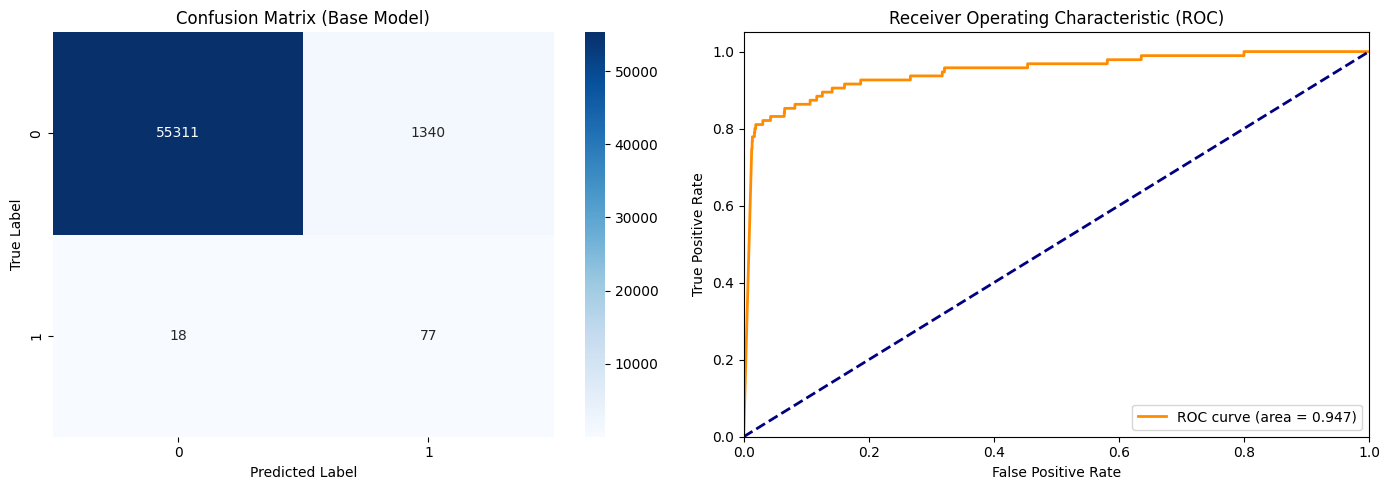

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_fraud_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix (Base Model)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_fraud_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

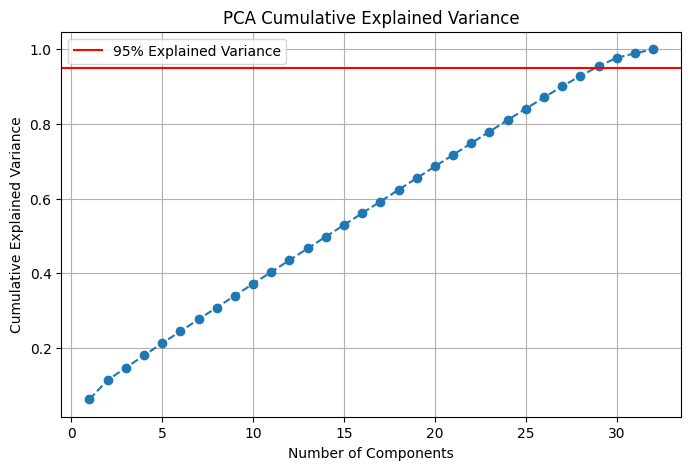

In [84]:
pca = PCA()
pca.fit(X_fraud_train)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

In [85]:
pca = PCA(n_components=28)

X_fraud_train_pca = pca.fit_transform(X_fraud_train)
X_fraud_test_pca = pca.transform(X_fraud_test)

print(f"Original features: {X_fraud_train.shape[1]}")
print(f"Reduced features (PCA): {X_fraud_train_pca.shape[1]}")

nb_pca = GaussianNB()
nb_pca.fit(X_fraud_train_pca, y_fraud_train)

y_pred_pca = nb_pca.predict(X_fraud_test_pca)
y_prob_pca = nb_pca.predict_proba(X_fraud_test_pca)[:, 1]


Original features: 32
Reduced features (PCA): 28


In [86]:
print("=== PCA MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_fraud_test, y_pred_pca):.4f}\n")
print("Classification Report:")
print(classification_report(y_fraud_test, y_pred_pca, zero_division=0))

=== PCA MODEL EVALUATION ===
Accuracy: 0.9764

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.05      0.81      0.10        95

    accuracy                           0.98     56746
   macro avg       0.53      0.89      0.55     56746
weighted avg       1.00      0.98      0.99     56746



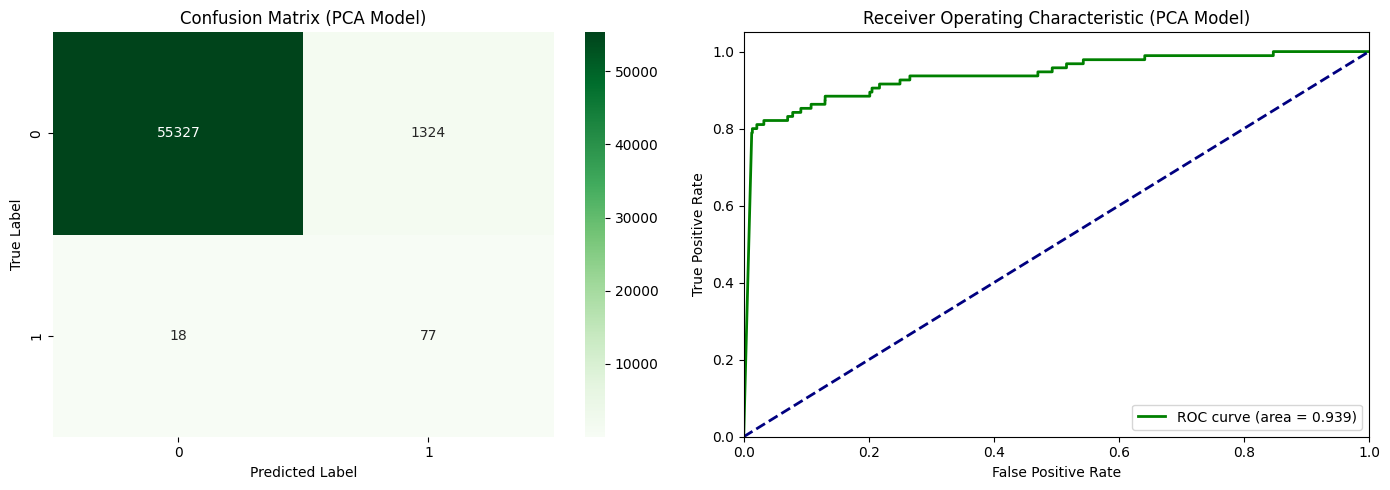

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm_pca = confusion_matrix(y_fraud_test, y_pred_pca)
sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Greens', ax=axes[0])
axes[0].set_title('Confusion Matrix (PCA Model)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr_pca, tpr_pca, thresholds_pca = roc_curve(y_fraud_test, y_prob_pca)
roc_auc_pca = auc(fpr_pca, tpr_pca)

axes[1].plot(fpr_pca, tpr_pca, color='green', lw=2, label=f'ROC curve (area = {roc_auc_pca:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (PCA Model)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## KNN Regressor

Applied to **Crypto Market Return Prediction**.

In [88]:
knn = KNeighborsRegressor(n_neighbors=10, p=2, weights="distance")
knn.fit(X_crypto_train_scaled, y_crypto_train)
y_crypto_test_pred = knn.predict(X_crypto_test_scaled)


In [89]:
test_r2  = r2_score(y_crypto_test, y_crypto_test_pred)
test_mae = mean_absolute_error(y_crypto_test, y_crypto_test_pred)
test_mse = mean_squared_error(y_crypto_test, y_crypto_test_pred)

print("=== KNN on scaled features (no PCA) ===")
print(f"R2 Score: {test_r2:.4f}")
print(f"MAE:      {test_mae:.6f}")
print(f"MSE:      {test_mse:.6f}")


=== KNN on scaled features (no PCA) ===
R2 Score: -0.0642
MAE:      0.076440
MSE:      0.012273


In [90]:
pca_crypto = PCA(n_components=0.95)
X_crypto_train_pca = pca_crypto.fit_transform(X_crypto_train_scaled)
X_crypto_test_pca  = pca_crypto.transform(X_crypto_test_scaled)

print(f"PCA: {X_crypto_train_scaled.shape[1]} features → {X_crypto_train_pca.shape[1]} components (95% variance)")


PCA: 20 features → 13 components (95% variance)


In [91]:
knn_pca = KNeighborsRegressor(n_neighbors=40, p=1)
knn_pca.fit(X_crypto_train_pca, y_crypto_train)
y_crypto_test_pred_pca = knn_pca.predict(X_crypto_test_pca)


In [92]:
test_r2_pca  = r2_score(y_crypto_test, y_crypto_test_pred_pca)
test_mae_pca = mean_absolute_error(y_crypto_test, y_crypto_test_pred_pca)
test_mse_pca = mean_squared_error(y_crypto_test, y_crypto_test_pred_pca)

print("=== KNN + PCA on scaled features ===")
print(f"R2 Score: {test_r2_pca:.4f}")
print(f"MAE:      {test_mae_pca:.6f}")
print(f"MSE:      {test_mse_pca:.6f}")


=== KNN + PCA on scaled features ===
R2 Score: 0.0199
MAE:      0.072937
MSE:      0.011303


## Ensemble Regressors

Applied to **Yahoo Finance Stock Return Prediction**.

In [93]:
# print("Initializing Final Models with Explicit Best Parameters...")

# # 1. Setup Final Random Forest (From Optuna Trial 58)
# best_params_rf = {
#     'n_estimators': 210,
#     'max_depth': 5,
#     'min_samples_split': 2,
#     'min_samples_leaf': 10,
#     'random_state': 42,
#     'n_jobs': -1
# }
# final_rf = RandomForestRegressor(**best_params_rf)

# print("Training Final Random Forest...")
# final_rf.fit(X_yahoo_train, y_stock_train)
# rf_predictions = final_rf.predict(X_yahoo_test)


In [94]:
# 2. Setup Final XGBoost (From Optuna Trial 11)
# best_params_xgb = {
#     'n_estimators': 380,
#     'learning_rate': 0.27926006434202694,
#     'max_depth': 6,
#     'subsample': 0.5218003352159574,
#     'colsample_bytree': 0.7341882687722235,
#     'min_child_weight': 1,
#     'gamma': 1.0703765890972565,
#     'reg_alpha': 0.016006678280215965,
#     'reg_lambda': 8.214406800943035,
#     'objective': 'reg:squarederror',
#     'random_state': 42,
#     'tree_method': 'hist',
#     'device': 'cuda'
# }
# final_xgb = XGBRegressor(**best_params_xgb)

# print("Training Final XGBoost...")
# final_xgb.fit(X_stock_train, y_stock_train)
# xgb_predictions = final_xgb.predict(X_stock_test)

In [95]:
# # 3. Print Evaluation Metrics
# print("\n--- Final Model Evaluation (Out-of-Sample) ---")
# print("RANDOM FOREST:")
# print(f"  MSE: {mean_squared_error(y_stock_test, rf_predictions):.6f}")
# print(f"  MAE: {mean_absolute_error(y_stock_test, rf_predictions):.6f}")
# print(f"  R2:  {r2_score(y_stock_test, rf_predictions):.4f}")

# print("\nXGBOOST:")
# print(f"  MSE: {mean_squared_error(y_stock_test, xgb_predictions):.6f}")
# print(f"  MAE: {mean_absolute_error(y_stock_test, xgb_predictions):.6f}")
# print(f"  R2:  {r2_score(y_stock_test, xgb_predictions):.4f}")

In [96]:
# # 4. Plotting Actuals vs Both Models
# plt.figure(figsize=(14, 7))
# days_to_plot = 100

# plt.plot(y_stock_test.values[-days_to_plot:], label='Actual Returns', color='black', marker='o', alpha=0.8, linewidth=2)
# plt.plot(rf_predictions[-days_to_plot:], label='Random Forest', color='green', marker='x', alpha=0.6, linestyle='--')
# plt.plot(xgb_predictions[-days_to_plot:], label='XGBoost', color='red', marker='s', alpha=0.6, linestyle='--')

# try:
#     ticker_name = sample_ticker
# except NameError:
#     ticker_name = "Stock"

# plt.title(f"{ticker_name} - Actual vs Predicted Daily Returns (Last 100 Days)")
# plt.xlabel("Days")
# plt.ylabel("Daily Percentage Return")
# plt.axhline(0, color='gray', linestyle='-', alpha=0.3)
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

# Autoencoder for Anomaly Detection

## Splitting and Isolation Normal and Fraud Data

In [97]:
X_fraud_train, X_fraud_test, y_fraud_train, y_fraud_test = train_test_split(
    X_fraud, y_fraud,
    test_size=0.2,
    random_state=42,
    stratify=y_fraud
)

# Isolate NORMAL data for training
X_train_normal = X_fraud_train[y_fraud_train == 0]
X_train_fraud = X_fraud_train[y_fraud_train == 1]
y_train_fraud = y_fraud_train[y_fraud_train == 1]

# Add the rescued fraud data to the test set
X_fraud_test = pd.concat([X_fraud_test, X_train_fraud], axis=0)
y_fraud_test = pd.concat([y_fraud_test, y_train_fraud], axis=0)

## AutoEncoder Structure and Training

In [98]:
input_dim = X_train_normal.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
encoder = Dense(16, activation="relu")(input_layer)
encoder = Dense(8, activation="relu")(encoder)

# Decoder
decoder = Dense(8, activation='relu')(encoder)
decoder = Dense(16, activation='relu')(decoder)

decoder = Dense(input_dim, activation='linear')(decoder)

autoencoder = Model(inputs=input_layer, outputs=decoder)

autoencoder.compile(optimizer='adam', loss='mean_squared_error')

history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=50,
    batch_size=32,
    shuffle=True,
    verbose=1
)

I0000 00:00:1776464036.996483      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Epoch 1/50


I0000 00:00:1776464039.824534     140 service.cc:152] XLA service 0x7b6830004fc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776464039.824566     140 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1776464040.154797     140 cuda_dnn.cc:529] Loaded cuDNN version 91002


  77/7082 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 8.5907

I0000 00:00:1776464040.893054     140 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


7082/7082 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 1.3253
Epoch 2/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.5881
Epoch 3/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.5466
Epoch 4/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 0.5037
Epoch 5/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4868
Epoch 6/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4724
Epoch 7/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4699
Epoch 8/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4703
Epoch 9/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4656
Epoch 10/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 0.4558
Epoch 11/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4463
Epoch 12/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4479
Epoch 13/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4425
Epoch 14/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.4427
Epoch 15/50
7082/7082 ━━━━

## Predictions

In [99]:
train_predictions = autoencoder.predict(X_train_normal)
mse_train = np.mean(np.power(X_train_normal - train_predictions, 2), axis=1)


best_threshold = np.percentile(mse_train, 99)

print(f"Statistically Calculated Threshold: {best_threshold}")

7082/7082 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
Statistically Calculated Threshold: 2.1094253758854844


## Evaluation

In [100]:
# Predict on the unseen test set
test_predictions = autoencoder.predict(X_fraud_test)
mse_test = np.mean(np.power(X_fraud_test - test_predictions, 2), axis=1)

# Classify as Fraud (1) if the error is higher than chosen threshold
y_test_pred = [1 if error > best_threshold else 0 for error in mse_test]

print(classification_report(y_fraud_test, y_test_pred))

1786/1786 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56651
           1       0.38      0.78      0.51       473

    accuracy                           0.99     57124
   macro avg       0.69      0.89      0.75     57124
weighted avg       0.99      0.99      0.99     57124



## Reconstruction Visualization

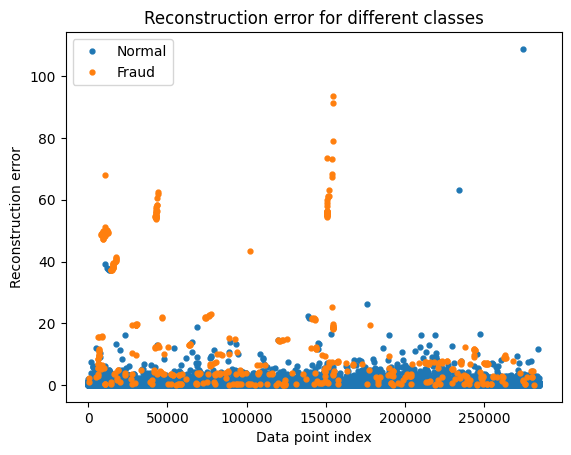

In [101]:
error_df = pd.DataFrame({'reconstruction_error': mse_test, 'true_class': y_fraud_test})

groups = error_df.groupby('true_class')
fig, ax = plt.subplots()

for name, group in groups:
    ax.plot(group.index, group.reconstruction_error, marker='o', ms=3.5, linestyle='',
            label= "Fraud" if name == 1 else "Normal")
ax.legend()
plt.title("Reconstruction error for different classes")
plt.ylabel("Reconstruction error")
plt.xlabel("Data point index")
plt.show()

## ROC-AUC Curve

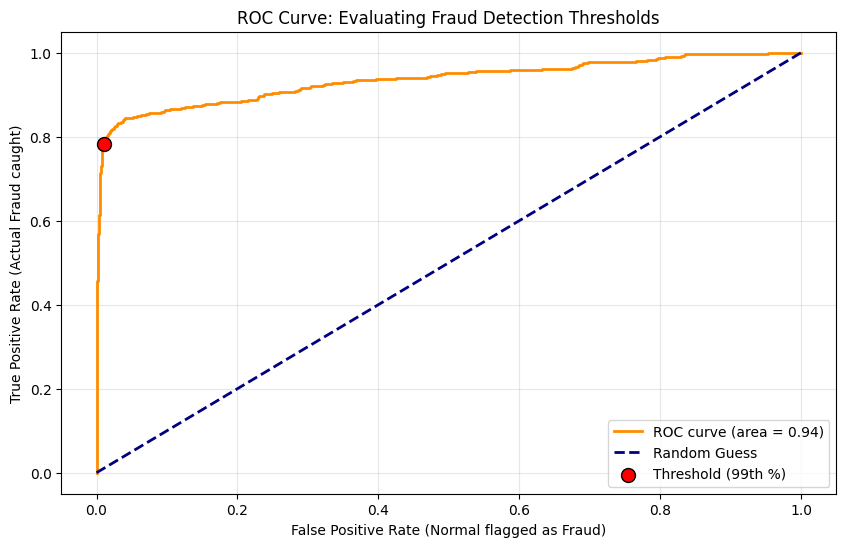

ROC-AUC Score: 0.9356
Threshold (2.1094) -> TPR: 0.78, FPR: 0.01


In [109]:
# 1. Calculate ROC metrics
fpr, tpr, thresholds = roc_curve(y_fraud_test, mse_test)
roc_auc = auc(fpr, tpr)

# 2. Calculate where the specific 99th percentile threshold sits on the curve
current_tpr = np.mean(mse_test[y_fraud_test == 1] > best_threshold)
current_fpr = np.mean(mse_test[y_fraud_test == 0] > best_threshold)

# 3. Visualization
plt.figure(figsize=(10, 6))

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

plt.scatter(current_fpr, current_tpr, color='red', s=100, edgecolors='black', zorder=5, 
            label=f'Threshold (99th %)')

plt.title('ROC Curve: Evaluating Fraud Detection Thresholds')
plt.xlabel('False Positive Rate (Normal flagged as Fraud)')
plt.ylabel('True Positive Rate (Actual Fraud caught)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")
print(f"Threshold ({best_threshold:.4f}) -> TPR: {current_tpr:.2f}, FPR: {current_fpr:.2f}")


# Transfer Learning

In [103]:
yahoo_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4208033 entries, 1245563 to 1690326
Data columns (total 23 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Date            object 
 1   Open            float64
 2   High            float64
 3   Low             float64
 4   Close           float64
 5   Volume          int64  
 6   Dividends       float64
 7   Stock Splits    float64
 8   Ticker          object 
 9   MA_5            float64
 10  MA_10           float64
 11  Daily_Return    float64
 12  rolling_mean_7  float64
 13  rolling_std_7   float64
 14  RSI_14          float64
 15  MACD_Line       float64
 16  MACD_Signal     float64
 17  MACD_hist       float64
 18  ATR             float64
 19  lag_1           float64
 20  lag_2           float64
 21  Volatility_10   float64
 22  target_price    float64
dtypes: float64(20), int64(1), object(2)
memory usage: 770.5+ MB


In [104]:
print(yahoo_data['Ticker'].unique())

['MSI' 'BA' 'KR' 'IBM' 'IP' 'GD' 'DIS' 'MO' 'MRK' 'DTE' 'HPQ' 'MMM' 'CVX'
 'JNJ' 'ED' 'CAT' 'PG' 'AEP' 'KO' 'XOM' 'GE' 'HON' 'CNP' 'MRO' 'RTX' 'MCD'
 'PCG' 'AXP' 'ETN' 'PFE' 'LLY' 'DD' 'TXN' 'BMY' 'ETR' 'DE' 'EMR' 'HAL' 'F'
 'WFC' 'PEP' 'WMT' 'AIG' 'TER' 'MKC' 'EVRG' 'NEE' 'TXT' 'CVS' 'CLX' 'PNW'
 'LNT' 'BALL' 'GWW' 'XEL' 'WHR' 'SPGI' 'SNA' 'VMC' 'AVY' 'TGT' 'RVTY'
 'CMS' 'BDX' 'BAC' 'ECL' 'K' 'MMC' 'NI' 'ES' 'CMI' 'CPB' 'ITW' 'EXC' 'CL'
 'MDT' 'WY' 'BK' 'PNR' 'FRT' 'USB' 'EIX' 'SYY' 'WRB' 'IFF' 'TAP' 'TRV'
 'PNC' 'C' 'LMT' 'FDX' 'WDC' 'DHR' 'APA' 'LUV' 'PEG' 'UNP' 'BIO' 'RHI'
 'HSY' 'GPC' 'MTB' 'SYK' 'SEE' 'APD' 'CAG' 'FMC' 'ALK' 'EFX' 'CHD' 'TSN'
 'RF' 'ADP' 'STT' 'VFC' 'LOW' 'EQT' 'TFX' 'DUK' 'CMA' 'HES' 'ADI' 'VTRS'
 'HRL' 'CINF' 'INTC' 'D' 'FITB' 'IPG' 'HAS' 'NUE' 'DOV' 'NTRS' 'NEM' 'LEN'
 'TMO' 'HST' 'ABT' 'PCAR' 'ADM' 'PH' 'PPG' 'ROL' 'L' 'PGR' 'CMCSA' 'WST'
 'SHW' 'TT' 'ZION' 'SWK' 'OMC' 'WEC' 'AMD' 'AFL' 'GIS' 'PHM' 'KMB' 'PPL'
 'AMAT' 'JPM' 'HBAN' 'BF-B' 'J' 'WBA' 'MAS' 'TYL'

In [105]:
yahoo_data['returns'].head()

KeyError: 'returns'

In [ ]:
# choose a source
source = "AAPL"
df_source = yahoo_data[yahoo_data["Ticker"] == source].copy()



In [ ]:
# order the data with Date
df_source = df_source.sort_values("Date")

In [ ]:
features = [
     'Volume',
    'MA_5', 'MA_10', 'Daily_Return',
    'RSI_14', 'MACD_Line', 'MACD_Signal', 'MACD_hist',
    'lag_1', 'lag_2', 'Volatility_10'
]

x = df_source[features].values
y = df_source['returns'].values

In [ ]:
print(x.shape)
print(y.shape)

In [ ]:
print(y[:10])

In [ ]:
st = StandardScaler()
x = st.fit_transform(x)

In [ ]:
# perpare the data for CNN
def squence(x,y,window = 30):
    x_sq = []
    y_sq = []
    for i in range(len(x) - window):
        x_sq.append(x[i:i+ window])
        y_sq.append(y[i+window])
    x_sq = np.array(x_sq)
    y_sq = np.array(y_sq)

    return x_sq,y_sq

x_sq, y_sq = squence(x,y)

In [ ]:
print(x_sq.shape)
print(y_sq.shape)

In [ ]:
# manual data Spliting
spilt_size =int(0.8 * len(x_sq))
x_train = x_sq[:spilt_size]
x_test = x_sq[spilt_size:]

y_train = y_sq[:spilt_size]
y_test = y_sq[spilt_size:]

In [ ]:
print(x_train.shape)
print(y_train.shape)
print("-----------------------")
print(y_train.shape)
print(y_test.shape)

In [ ]:
# Bulild CNN Model
model_scratch = Sequential([
    Conv1D(64,3,activation='relu',input_shape=(30,x_sq.shape[2])),
    MaxPooling1D(2),

    Conv1D(128,3,activation='relu'),
    MaxPooling1D(2),

    Flatten(),

    Dense(50,activation='relu'),
    Dropout(0.2),

    Dense(1)
])

model_scratch.compile(
    optimizer = 'adam',
    loss = 'mse',
    metrics = ['mae']
)

In [ ]:
history = model_scratch.fit(
    x_train,y_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (x_test,y_test)
)

In [ ]:
# Evaluate scratch model
scratch_loss, scratch_MAE = model_scratch.evaluate(x_test, y_test, verbose=0)

# Predict probabilities
y_pred_scratch = model_scratch.predict(x_test).ravel()

In [ ]:
# freeze some layers
for layer in model_scratch.layers[:-2]:
    layer.trainable = False


In [ ]:
# try anothor source
source = "TSLA"
df_source2 = yahoo_data[yahoo_data["Ticker"] == source].copy()
df_source2 = df_source2.sort_values("Date")


In [ ]:
x_t = df_source2[features].values
y_t = df_source2['returns'].values


In [ ]:
st = StandardScaler()
x_t = st.fit_transform(x_t)


x_t_sq,y_t_sq = squence(x_t,y_t)


In [ ]:
spilt_size =int(0.8 * len(x_t_sq))
x_t_train = x_t_sq[:spilt_size]
x_t_test = x_t_sq[spilt_size:]

y_t_train = y_t_sq[:spilt_size]
y_t_test = y_t_sq[spilt_size:]

In [ ]:
model_finetuned = model_scratch.fit(
    x_t_train,y_t_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (x_t_test,y_t_test)
)

In [ ]:
# Evaluate fine-tuned model
finetuned_loss, finetuned_MAE = model_finetuned.evaluate(x_t_test, y_t_test, verbose=0)

# Predict probabilities
y_pred_finetuned = model_finetuned.predict(x_t_test).ravel()

In [ ]:
mse_scratch = mean_squared_error(y_test, y_pred_scratch)
rmse_scratch = np.sqrt(mse_scratch)
mae_scratch = mean_absolute_error(y_test, y_pred_scratch)
r2_scratch = r2_score(y_test, y_pred_scratch)

In [ ]:
mse_fine = mean_squared_error(y_t_test, y_pred_finetuned)
rmse_fine = np.sqrt(mse_fine)
mae_fine = mean_absolute_error(y_t_test, y_pred_finetuned)
r2_fine = r2_score(y_t_test, y_pred_finetuned)

In [ ]:
comparison_table = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R²"],
    "Cold Start (Scratch)": [mse_scratch, rmse_scratch, mae_scratch, r2_scratch],
    "Fine-Tuned": [mse_fine, rmse_fine, mae_fine, r2_fine]
})

comparison_table